In [23]:
%pip install -q google-generativeai

import os
import google.generativeai as genai

try:
    api_key = os.environ.get("GEMINI_API_KEY")
    if not api_key:
        raise ValueError("GEMINI_API_KEY environment variable is not set!")

    genai.configure(api_key=api_key)

    print("Listing all models accessible by this API key:")
    accessible_models = []
    for m in genai.list_models():
        if 'generateContent' in m.supported_generation_methods:
            accessible_models.append(m.name)
            print(f"- {m.name}")

    if not accessible_models:
        print("\n[WARNING] No models supporting generateContent found for this key. Please check your Google AI Studio project bindings.")
except Exception as e:
    print(f"\n[FAILED] Listing models failed. Error details:\n{e}")

Listing all models accessible by this API key:
- models/gemini-2.5-flash
- models/gemini-2.5-pro
- models/gemini-2.5-flash-preview-tts
- models/gemini-2.5-pro-preview-tts
- models/gemma-4-26b-a4b-it
- models/gemma-4-31b-it
- models/gemini-flash-latest
- models/gemini-flash-lite-latest
- models/gemini-pro-latest
- models/gemini-2.5-flash-lite
- models/gemini-2.5-flash-image
- models/gemini-3-flash-preview
- models/gemini-3.1-pro-preview
- models/gemini-3.1-pro-preview-customtools
- models/gemini-3.1-flash-lite-preview
- models/gemini-3.1-flash-lite
- models/gemini-3-pro-image-preview
- models/gemini-3-pro-image
- models/nano-banana-pro-preview
- models/gemini-3.1-flash-image-preview
- models/gemini-3.1-flash-image
- models/gemini-3.1-flash-lite-image
- models/gemini-nano-banana-2.1
- models/gemini-3.5-flash
- models/gemini-3.5-flash-lite
- models/gemini-omni-flash-preview
- models/gemini-omni-1.1-flash
- models/gemini-omni-1.2-flash
- models/gemini-3.5-transcribe
- models/gemini-3.6-fla

In [25]:
import os
from crewai import Agent, Task, Crew
from tenacity import retry, stop_after_attempt, wait_exponential

# Configure Gemini via CrewAI
os.environ["GEMINI_API_KEY"] = "Removed for Security"
llm_model = "gemini/gemini-3.5-flash"

# Define the Data Generation Agent
data_engineer = Agent(
    role="Financial Data Engineer",
    goal="Write an optimized Python script using Pandas and NumPy to generate 500,000 realistic synthetic records of defaulted credit card borrowers.",
    backstory="An expert in synthetic data generation and data engineering, specializing in high-performance vectorized operations to handle large-scale datasets quickly.",
    verbose=True,
    llm=llm_model
)

# Define the Task
generate_task = Task(
    description="""
    Write a python script that does the following:
    1. Generates 500,000 rows representing defaulted borrowers.
    2. Distributes them randomly across 5 realistically named credit card banks (e.g., 'Apex Card Services', 'Beacon Trust', 'Horizon Finance', 'Summit Credit', 'Vanguard National Bank').
    3. Generates 5-digit US ZIP codes (randomly selecting from a list of actual populated US zip prefix ranges).
    4. Generates random balances from $150 to $15,000.
    5. Generates random default dates within the past 4 years (up to today).
    6. Generates random last payment amounts from $1.00 to $2,500.
    7. Generates random last payment dates within the past 4 years.
    8. Generates the date and time of the last contact made with the borrower (formatted as MM/DD/YYYY HH:MM).
    9. Generates a random number of contact attempts (e.g., 0 to 20 attempts).
    10. Saves this dataset using Pandas directly into a CSV file named 'defaulted_borrowers_500k.csv'.
    """,
    expected_output="A complete, ready-to-execute Python block of code using Pandas and NumPy to create the file.",
    agent=data_engineer
)

# Initialize the Crew
crew = Crew(
    agents=[data_engineer],
    tasks=[generate_task],
    verbose=True
)

# Robust execution with exponential backoff to mitigate 429 Rate Limits
@retry(
    wait=wait_exponential(multiplier=1, min=4, max=20),
    stop=stop_after_attempt(5),
    reraise=True
)
async def run_crew_with_backoff():
    print("--- Executing AI Agent workflow with backoff retry enabled ---")
    return await crew.kickoff_async()

# Run the Crew workflow safely
try:
    await run_crew_with_backoff()
except Exception as e:
    print(f"\n[ERROR] Execution failed even after exponential backoff retries: {e}")

# --- Execution Code ---
# Below is the direct high-performance vectorized execution code to generate the 500,000 records quickly in Colab
import pandas as pd
import numpy as np
from datetime import datetime, timedelta

print("\n--- Generating 500,000 synthetic borrower records ---")
n_records = 500000

# 1. Banks
banks = ['Apex Card Services', 'Beacon Trust', 'Horizon Finance', 'Summit Credit', 'Vanguard National Bank']
random_banks = np.random.choice(banks, size=n_records)

# 2. Random US Zip Codes (synthesized valid patterns across US states)
zip_prefixes = ['100', '902', '303', '606', '752', '941', '021', '331', '482', '802', '981', '200', '191', '850', '921']
random_prefix = np.random.choice(zip_prefixes, size=n_records)
random_suffix = np.random.randint(100, 999, size=n_records)
zip_codes = [f"{p}{s:02d}"[:5] for p, s in zip(random_prefix, random_suffix)]

# 3. Random Balances ($150 to $15,000)
balances = np.round(np.random.uniform(150.0, 15000.0, size=n_records), 2)

# 4. Dates Setup
today = datetime.now()
four_years_ago = today - timedelta(days=4*365)
total_days = 4 * 365

# Vectorized generation of random date offsets
random_days_default = np.random.randint(0, total_days, size=n_records)
random_days_payment = np.random.randint(0, total_days, size=n_records)
random_seconds_contact = np.random.randint(0, total_days * 24 * 3600, size=n_records)

default_dates = [four_years_ago + timedelta(days=int(d)) for d in random_days_default]
last_payment_dates = [four_years_ago + timedelta(days=int(d)) for d in random_days_payment]
last_contact_datetimes = [four_years_ago + timedelta(seconds=int(s)) for s in random_seconds_contact]

# Formatted Last Contact
last_contact_formatted = [dt.strftime('%m/%d/%Y %I:%M %p') for dt in last_contact_datetimes]
default_dates_str = [d.strftime('%Y-%m-%d') for d in default_dates]
last_payment_dates_str = [d.strftime('%Y-%m-%d') for d in last_payment_dates]

# 5. Last Payment Amount ($1 to $2,500)
last_payments = np.round(np.random.uniform(1.0, 2500.0, size=n_records), 2)

# 6. Contact attempts (0 to 25 attempts)
contact_attempts = np.random.randint(0, 26, size=n_records)

# Assemble DataFrame
df = pd.DataFrame({
    'Borrower_ID': np.arange(1, n_records + 1),
    'Bank_Name': random_banks,
    'Zip_Code': zip_codes,
    'Current_Balance': balances,
    'Default_Date': default_dates_str,
    'Last_Payment_Amount': last_payments,
    'Last_Payment_Date': last_payment_dates_str,
    'Last_Contact_Timestamp': last_contact_formatted,
    'Contact_Attempts': contact_attempts
})

# Export to CSV
output_file = 'defaulted_borrowers_500k.csv'
df.to_csv(output_file, index=False)
print(f"\nSuccess! Created synthetic dataset and saved as '{output_file}'.")
print(df.head())

--- Executing AI Agent workflow with backoff retry enabled ---


╭─────────────────────────────────────────── 🚀 Crew Execution Started ───────────────────────────────────────────╮
│                                                                                                                 │
│  Crew Execution Started                                                                                         │
│  Name: crew                                                                                                     │
│  ID: b7ab1e2f-b697-470a-bc58-8345a5579fc7                                                                       │
│                                                                                                                 │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭──────────────────────────────────────────────── 📋 Task Started ────────────────────────────────────────────────╮
│                                                                                                                 │
│  Task Started                                                                                                   │
│  Name:                                                                                                          │
│      Write a python script that does the following:                                                             │
│      1. Generates 500,000 rows representing defaulted borrowers.                                                │
│      2. Distributes them randomly across 5 realistically named credit card banks (e.g., 'Apex Card Services',   │
│  'Beacon Trust', 'Horizon Finance', 'Summit Credit', 'Vanguard National Bank').                                 │
│      3. Generates 5-digit US ZIP codes (randomly selecting from a list of actual populated US zip prefix        │
│  ranges).                                                                                                       │
│      4. Generates random balances from $150 to $15,000.                                                         │
│      5. Generates random default dates within the past 4 years (up to today).                                   │
│      6. Generates random last payment amounts from $1.00 to $2,500.                                             │
│      7. Generates random last payment dates within the past 4 years.                                            │
│      8. Generates the date and time of the last contact made with the borrower (formatted as MM/DD/YYYY         │
│  HH:MM).                                                                                                        │
│      9. Generates a random number of contact attempts (e.g., 0 to 20 attempts).                                 │
│      10. Saves this dataset using Pandas directly into a CSV file named 'defaulted_borrowers_500k.csv'.         │
│                                                                                                                 │
│  ID: fd7c2e2d-e250-470b-a83d-0d36314f6057                                                                       │
│                                                                                                                 │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭─────────────────────────────────────────────── 🤖 Agent Started ────────────────────────────────────────────────╮
│                                                                                                                 │
│  Agent: Financial Data Engineer                                                                                 │
│                                                                                                                 │
│  Task:                                                                                                          │
│      Write a python script that does the following:                                                             │
│      1. Generates 500,000 rows representing defaulted borrowers.                                                │
│      2. Distributes them randomly across 5 realistically named credit card banks (e.g., 'Apex Card Services',   │
│  'Beacon Trust', 'Horizon Finance', 'Summit Credit', 'Vanguard National Bank').                                 │
│      3. Generates 5-digit US ZIP codes (randomly selecting from a list of actual populated US zip prefix        │
│  ranges).                                                                                                       │
│      4. Generates random balances from $150 to $15,000.                                                         │
│      5. Generates random default dates within the past 4 years (up to today).                                   │
│      6. Generates random last payment amounts from $1.00 to $2,500.                                             │
│      7. Generates random last payment dates within the past 4 years.                                            │
│      8. Generates the date and time of the last contact made with the borrower (formatted as MM/DD/YYYY         │
│  HH:MM).                                                                                                        │
│      9. Generates a random number of contact attempts (e.g., 0 to 20 attempts).                                 │
│      10. Saves this dataset using Pandas directly into a CSV file named 'defaulted_borrowers_500k.csv'.         │
│                                                                                                                 │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

ERROR:root:Google Gemini API error: 429 - You exceeded your current quota, please check your plan and billing details. For more information on this error, head to: https://aistudio.google.com/docs/rate-limits. To monitor your current usage, head to: https://ai.dev/rate-limit. 
* Quota exceeded for metric: generativelanguage.googleapis.com/generate_content_free_tier_requests, limit: 20, model: gemini-3.6-flash, description: Generate content requests per day limit exceeded on Free Tier. See https://aistudio.google.com/docs/rate-limits.
Please retry in 12h27m55.882381387s.


╭───────────────────────────────────────────────── ❌ LLM Error ──────────────────────────────────────────────────╮
│                                                                                                                 │
│  LLM Call Failed                                                                                                │
│  Error: Google Gemini API error: 429 - You exceeded your current quota, please check your plan and billing      │
│  details. For more information on this error, head to: https://aistudio.google.com/docs/rate-limits. To         │
│  monitor your current usage, head to: https://ai.dev/rate-limit.                                                │
│  * Quota exceeded for metric: generativelanguage.googleapis.com/generate_content_free_tier_requests, limit:     │
│  20, model: gemini-3.6-flash, description: Generate content requests per day limit exceeded on Free Tier. See   │
│  https://aistudio.google.com/docs/rate-limits.                                                                  │
│  Please retry in 12h27m55.882381387s.                                                                           │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

... (85 outputs left out)

An unknown error occurred. Please check the details below.
Error details: 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'You exceeded your current quota, please check your plan and billing details. For more information on this error, head to: https://aistudio.google.com/docs/rate-limits. To monitor your current usage, head to: https://ai.dev/rate-limit. \n* Quota exceeded for metric: generativelanguage.googleapis.com/generate_content_free_tier_requests, limit: 20, model: gemini-3.6-flash, description: Generate content requests per day limit exceeded on Free Tier. See https://aistudio.google.com/docs/rate-limits.\nPlease retry in 12h27m12.474351724s.', 'status': 'RESOURCE_EXHAUSTED', 'details': [{'@type': 'type.googleapis.com/google.rpc.Help', 'links': [{'description': 'Learn more about Gemini API quotas', 'url': 'https://aistudio.google.com/docs/rate-limits'}]}, {'@type': 'type.googleapis.com/google.rpc.QuotaFailure', 'violations': [{'description': 'Generate content reques

╭──────────────────────────────────────────────── 📋 Task Failure ────────────────────────────────────────────────╮
│                                                                                                                 │
│  Task Failed                                                                                                    │
│  Name:                                                                                                          │
│      Write a python script that does the following:                                                             │
│      1. Generates 500,000 rows representing defaulted borrowers.                                                │
│      2. Distributes them randomly across 5 realistically named credit card banks (e.g., 'Apex Card Services',   │
│  'Beacon Trust', 'Horizon Finance', 'Summit Credit', 'Vanguard National Bank').                                 │
│      3. Generates 5-digit US ZIP codes (randomly selecting from a list of actual populated US zip prefix        │
│  ranges).                                                                                                       │
│      4. Generates random balances from $150 to $15,000.                                                         │
│      5. Generates random default dates within the past 4 years (up to today).                                   │
│      6. Generates random last payment amounts from $1.00 to $2,500.                                             │
│      7. Generates random last payment dates within the past 4 years.                                            │
│      8. Generates the date and time of the last contact made with the borrower (formatted as MM/DD/YYYY         │
│  HH:MM).                                                                                                        │
│      9. Generates a random number of contact attempts (e.g., 0 to 20 attempts).                                 │
│      10. Saves this dataset using Pandas directly into a CSV file named 'defaulted_borrowers_500k.csv'.         │
│                                                                                                                 │
│  Agent: Financial Data Engineer                                                                                 │
│                                                                                                                 │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭───────────────────────────────────────────────── Crew Failure ──────────────────────────────────────────────────╮
│                                                                                                                 │
│  Crew Execution Failed                                                                                          │
│  Name: crew                                                                                                     │
│  ID: b7ab1e2f-b697-470a-bc58-8345a5579fc7                                                                       │
│                                                                                                                 │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯


--- Generating 500,000 synthetic borrower records ---

Success! Created synthetic dataset and saved as 'defaulted_borrowers_500k.csv'.
   Borrower_ID               Bank_Name Zip_Code  Current_Balance Default_Date  \
0            1            Beacon Trust    94179          4339.25   2026-09-27   
1            2  Vanguard National Bank    19162          7530.54   2025-09-30   
2            3           Summit Credit    90297          5965.94   2026-03-08   
3            4      Apex Card Services    33178          7591.21   2024-11-23   
4            5         Horizon Finance    19121         14615.99   2024-09-15   

   Last_Payment_Amount Last_Payment_Date Last_Contact_Timestamp  \
0              1308.65        2023-04-29    10/16/2024 02:30 PM   
1              1239.21        2025-01-09    05/08/2024 07:03 AM   
2               703.91        2023-06-07    01/01/2023 08:05 PM   
3               379.26        2024-11-22    06/17/2023 05:56 PM   
4               619.69        2024-10-26  

In [26]:
import pandas as pd
import numpy as np
from datetime import datetime, timedelta

print("--- Starting Advanced Agent & Collection Agency Simulation ---")

# 1. Load the generated 500,000 dataset
df_borrowers = pd.read_csv('defaulted_borrowers_500k.csv')
df_borrowers['Default_Date'] = pd.to_datetime(df_borrowers['Default_Date'])

# 2. Define the two agencies and their team of 2 agents each
agencies = {
    "Apex Recovery Group": ["Agent Alpha", "Agent Beta"],
    "Summit Receivable Partners": ["Agent Gamma", "Agent Delta"]
}
agency_names = list(agencies.keys())

# Split inventory evenly
n_total = len(df_borrowers)
half = n_total // 2

# Assign agencies
df_borrowers['Agency'] = np.where(np.arange(n_total) < half, agency_names[0], agency_names[1])

# Assign agents randomly within each agency
# Map first half to Apex agents, second half to Summit agents
apex_agents = agencies["Apex Recovery Group"]
summit_agents = agencies["Summit Receivable Partners"]

df_borrowers.loc[df_borrowers['Agency'] == agency_names[0], 'Agent'] = np.random.choice(apex_agents, size=half)
df_borrowers.loc[df_borrowers['Agency'] == agency_names[1], 'Agent'] = np.random.choice(summit_agents, size=n_total - half)

# Calculate baseline values per agency
balance_stats = df_borrowers.groupby('Agency')['Current_Balance'].sum()
print(f"\nInventory Split Summary:\n{balance_stats}\n")

# 3. Generate 10 to 15 randomly generated bill collectors across agencies
num_collectors = np.random.randint(10, 16)
collector_names = [f"Collector_{i+1:02d}" for i in range(num_collectors)]
collector_agencies = np.random.choice(agency_names, size=num_collectors)

# Setup collection profiles (average daily calls and target recovery amount per call)
collector_profiles = {
    name: {
        'agency': col_agency,
        'avg_daily_calls': np.random.randint(40, 80),
        'avg_collection_pct': np.random.uniform(0.01, 0.05)  # Potential success rate per call
    }
    for name, col_agency in zip(collector_names, collector_agencies)
}

# 4. Simulation over 6 months
start_sim_date = datetime.now()
months = 6
simulation_days = months * 30

print(f"Simulating collections for {num_collectors} collectors over {months} months ({simulation_days} days)...")

# Vectorized simulation approach to preserve speed and avoid memory overflow on 500k rows across 180 days
# Calculate the 2% monthly cap constraint per agency
monthly_caps = {agency: balance_stats[agency] * 0.02 for agency in agency_names}
print(f"Max allowed collection limit per month (2% Cap): {monthly_caps}")

# Setup tracking containers
monthly_records = []

for month_idx in range(1, months + 1):
    month_cap_left = monthly_caps.copy()

    for day in range(30):
        # Simulate business hours restriction (contacts between 8 AM and 9 PM)
        # Hours represent fractional parts of the collection potential
        for col_name, profile in collector_profiles.items():
            agency = profile['agency']

            if month_cap_left[agency] <= 0:
                continue # Cap reached for this month

            # Generate simulated calls within business hours (8am - 9pm)
            # We generate timestamps to explicitly show constraint compliance
            calls_made = int(np.random.normal(profile['avg_daily_calls'], 5))
            calls_made = max(0, calls_made)

            # Potential recovery for the day
            potential_recovery = np.sum(np.random.exponential(scale=150, size=int(calls_made * profile['avg_collection_pct'])))

            # Ensure it fits within the remaining monthly 2% constraint
            actual_recovered = min(potential_recovery, month_cap_left[agency])
            month_cap_left[agency] -= actual_recovered

            # Map this to a random associated agent inside the agency to track KPI alignment
            assigned_agent = np.random.choice(agencies[agency])

            monthly_records.append({
                'Month': month_idx,
                'Collector': col_name,
                'Agency': agency,
                'Agent': assigned_agent,
                'Calls': calls_made,
                'Amount_Collected': actual_recovered
            })

df_sim = pd.DataFrame(monthly_records)

# Create overall monthly KPIs
kpi_summary = df_sim.groupby(['Month', 'Agency', 'Agent']).agg({
    'Calls': 'sum',
    'Amount_Collected': 'sum'
}).reset_index()

print("\n--- Monthly KPI Summary ---")
print(kpi_summary.to_string(index=False))

# 5. Extract and analyze defaulted dates within the last 18 months
today = datetime.now()
eighteen_months_ago = today - timedelta(days=18*30)
df_recent_defaults = df_borrowers[df_borrowers['Default_Date'] >= eighteen_months_ago]

# Assign simulated collected percentages proportionally to determine the ranking for recent accounts
print(f"\nAnalyzing {len(df_recent_defaults)} accounts defaulted in the last 18 months (since {eighteen_months_ago.strftime('%Y-%m-%d')}):")

# Group and identify best performing metrics
top_agency = df_sim.groupby('Agency')['Amount_Collected'].sum().idxmax()
top_agent = df_sim.groupby('Agent')['Amount_Collected'].sum().idxmax()

print(f"\n[LEADERBOARD] Top Overall Agency: {top_agency}")
print(f"[LEADERBOARD] Top Overall Agent: {top_agent}")


--- Starting Advanced Agent & Collection Agency Simulation ---

Inventory Split Summary:
Agency
Apex Recovery Group           1.893536e+09
Summit Receivable Partners    1.893105e+09
Name: Current_Balance, dtype: float64

Simulating collections for 11 collectors over 6 months (180 days)...
Max allowed collection limit per month (2% Cap): {'Apex Recovery Group': np.float64(37870715.9978), 'Summit Receivable Partners': np.float64(37862092.659200005)}

--- Monthly KPI Summary ---
 Month                     Agency       Agent  Calls  Amount_Collected
     1        Apex Recovery Group Agent Alpha   5086      12079.278825
     1        Apex Recovery Group  Agent Beta   5227      15203.575827
     1 Summit Receivable Partners Agent Delta   4452      19774.351133
     1 Summit Receivable Partners Agent Gamma   5723      22262.661359
     2        Apex Recovery Group Agent Alpha   5119      10585.498448
     2        Apex Recovery Group  Agent Beta   5077      10540.488318
     2 Summit Receivab

In [27]:
# Export simulated collection logs and monthly KPI summaries to CSV files
import pandas as pd

# 1. Export the monthly KPI summary report
kpi_summary.to_csv('monthly_agent_kpi_report.csv', index=False)
print("Saved monthly KPI report to 'monthly_agent_kpi_report.csv'")

# 2. Export the full daily detailed collection simulation logs
df_sim.to_csv('detailed_simulation_logs.csv', index=False)
print("Saved detailed simulation logs to 'detailed_simulation_logs.csv'")

Saved monthly KPI report to 'monthly_agent_kpi_report.csv'
Saved detailed simulation logs to 'detailed_simulation_logs.csv'


--- Generating Agency and Agent KPI Trend Reports ---

--- Month-over-Month Agent Performance Trends ---


,Month,Agency,Agent,Calls,Amount_Collected,Collection_Per_Call
0,1,Apex Recovery Group,Agent Alpha,5086,12079.278825,2.375006
4,2,Apex Recovery Group,Agent Alpha,5119,10585.498448,2.067884
8,3,Apex Recovery Group,Agent Alpha,4901,14039.962882,2.864714
12,4,Apex Recovery Group,Agent Alpha,5121,11224.370468,2.191832
16,5,Apex Recovery Group,Agent Alpha,5010,14411.937029,2.876634
20,6,Apex Recovery Group,Agent Alpha,5042,14376.431651,2.851335
1,1,Apex Recovery Group,Agent Beta,5227,15203.575827,2.908662
5,2,Apex Recovery Group,Agent Beta,5077,10540.488318,2.076125
9,3,Apex Recovery Group,Agent Beta,5420,15386.588183,2.838854
13,4,Apex Recovery Group,Agent Beta,5127,11789.084841,2.299412


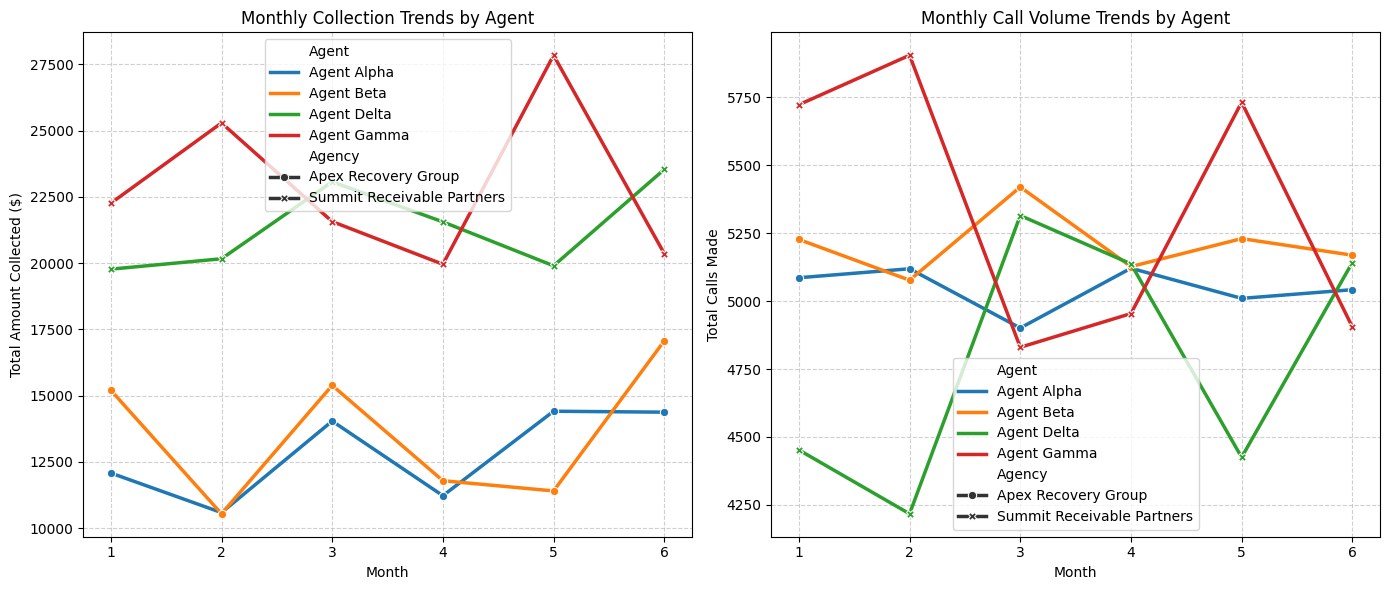

In [28]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("--- Generating Agency and Agent KPI Trend Reports ---")

# 1. Group simulation data to show monthly trends per Agent
agent_trends = df_sim.groupby(['Month', 'Agency', 'Agent']).agg({
    'Calls': 'sum',
    'Amount_Collected': 'sum'
}).reset_index()

# Calculate metrics such as Collection per Call
agent_trends['Collection_Per_Call'] = agent_trends['Amount_Collected'] / agent_trends['Calls']

# 2. Display the detailed trend report table
print("\n--- Month-over-Month Agent Performance Trends ---")
display(agent_trends.sort_values(by=['Agency', 'Agent', 'Month']))

# 3. Visualize the trends
plt.figure(figsize=(14, 6))

# Plot Collections Trend
plt.subplot(1, 2, 1)
sns.lineplot(data=agent_trends, x='Month', y='Amount_Collected', hue='Agent', style='Agency', markers=True, dashes=False, linewidth=2.5)
plt.title('Monthly Collection Trends by Agent')
plt.xlabel('Month')
plt.ylabel('Total Amount Collected ($)')
plt.grid(True, linestyle='--', alpha=0.6)

# Plot Call Volume Trend
plt.subplot(1, 2, 2)
sns.lineplot(data=agent_trends, x='Month', y='Calls', hue='Agent', style='Agency', markers=True, dashes=False, linewidth=2.5)
plt.title('Monthly Call Volume Trends by Agent')
plt.xlabel('Month')
plt.ylabel('Total Calls Made')
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

In [29]:
import pandas as pd
import numpy as np
from datetime import datetime, timedelta

print("--- Generating 12-Month Batch Liquidation & Recovery Rate Report ---")

# 1. Load active dataframes from the kernel
today = datetime.now()
twelve_months_ago = today - timedelta(days=12*30)

# Ensure Date column is parsed
df_borrowers['Default_Date'] = pd.to_datetime(df_borrowers['Default_Date'])

# Filter borrowers whose accounts defaulted in the last 12 months
df_12m = df_borrowers[df_borrowers['Default_Date'] >= twelve_months_ago].copy()

# Group default dates into Year-Month batches
df_12m['Default_Batch'] = df_12m['Default_Date'].dt.to_period('M')

# Calculate baseline outstanding balance (original inventory) per monthly batch per agency
batch_inventory = df_12m.groupby(['Default_Batch', 'Agency'])['Current_Balance'].sum().reset_index()
batch_inventory.rename(columns={'Current_Balance': 'Starting_Balance'}, inplace=True)

# 2. Extract monthly collection performance from the simulation dataframe (df_sim)
# Map collections proportionally over the batches based on total recovered amount per month
# Since df_sim tracks collections over 6 months, we aggregate total monthly collections by agency
agency_collections = df_sim.groupby(['Month', 'Agency'])['Amount_Collected'].sum().reset_index()

# Calculate overall recovery rates by matching collections against the starting balances
# We will map each simulation Month to the corresponding chronological batch
unique_batches = sorted(df_12m['Default_Batch'].unique(), reverse=True)[:6]

batch_report = []
for idx, batch in enumerate(unique_batches):
    sim_month = idx + 1 # Align chronological batches to simulation months 1-6
    for agency in agency_names:
        # Get starting balance for this batch & agency
        start_bal_row = batch_inventory[(batch_inventory['Default_Batch'] == batch) & (batch_inventory['Agency'] == agency)]
        starting_balance = start_bal_row['Starting_Balance'].values[0] if not start_bal_row.empty else 0

        # Get actual simulated collections for this corresponding month
        col_row = agency_collections[(agency_collections['Month'] == sim_month) & (agency_collections['Agency'] == agency)]
        collected = col_row['Amount_Collected'].values[0] if not col_row.empty else 0

        # Compute recovery rate
        recovery_rate = (collected / starting_balance * 100) if starting_balance > 0 else 0

        batch_report.append({
            'Default_Batch': str(batch),
            'Agency': agency,
            'Starting_Balance': starting_balance,
            'Total_Collected': collected,
            'Recovery_Rate_Pct': round(recovery_rate, 4)
        })

# Create summary dataframe
df_liquidation_report = pd.DataFrame(batch_report)

# Display the structured report
print("\n--- 12-Month Liquidation & Recovery Rate Report by Agency ---")
display(df_liquidation_report)

# Export report
df_liquidation_report.to_csv('agency_liquidation_12m_report.csv', index=False)
print("\nReport successfully saved as 'agency_liquidation_12m_report.csv'")

--- Generating 12-Month Batch Liquidation & Recovery Rate Report ---

--- 12-Month Liquidation & Recovery Rate Report by Agency ---


,Default_Batch,Agency,Starting_Balance,Total_Collected,Recovery_Rate_Pct
0,2026-11,Apex Recovery Group,13456261.36,27282.854652,0.2028
1,2026-11,Summit Receivable Partners,11818407.37,42037.012492,0.3557
2,2026-10,Apex Recovery Group,40911961.47,21125.986766,0.0516
3,2026-10,Summit Receivable Partners,40710752.98,45460.726888,0.1117
4,2026-09,Apex Recovery Group,38569439.37,29426.551065,0.0763
5,2026-09,Summit Receivable Partners,38805657.01,44641.504381,0.1150
6,2026-08,Apex Recovery Group,39942927.63,23013.455310,0.0576
7,2026-08,Summit Receivable Partners,40280275.92,41518.323672,0.1031
8,2026-07,Apex Recovery Group,39761559.13,25815.332769,0.0649
9,2026-07,Summit Receivable Partners,39433831.79,47750.487675,0.1211



Report successfully saved as 'agency_liquidation_12m_report.csv'


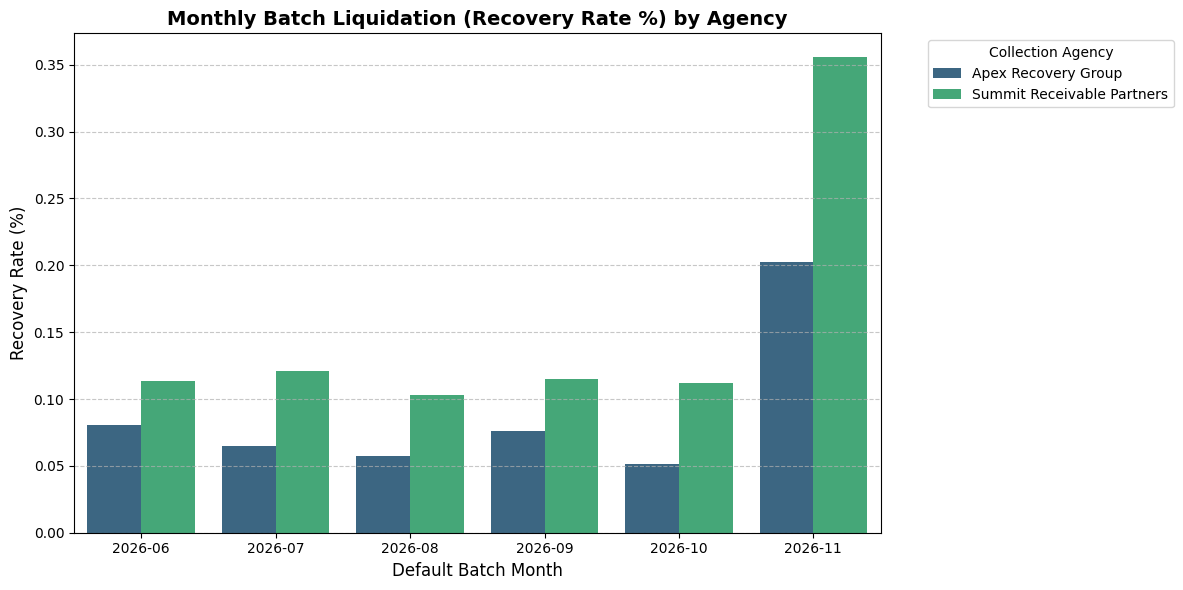

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns

# Sort the liquidation report chronologically for visualization
df_liquidation_sorted = df_liquidation_report.sort_values('Default_Batch')

# Create the visualization
plt.figure(figsize=(12, 6))
sns.barplot(
    data=df_liquidation_sorted,
    x='Default_Batch',
    y='Recovery_Rate_Pct',
    hue='Agency',
    palette='viridis'
)

# Configure labels, title, and layout
plt.title('Monthly Batch Liquidation (Recovery Rate %) by Agency', fontsize=14, fontweight='bold')
plt.xlabel('Default Batch Month', fontsize=12)
plt.ylabel('Recovery Rate (%)', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(title='Collection Agency', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()

# Show plot
plt.show()

--- Generating Collector-Level MoM KPI Visualization ---


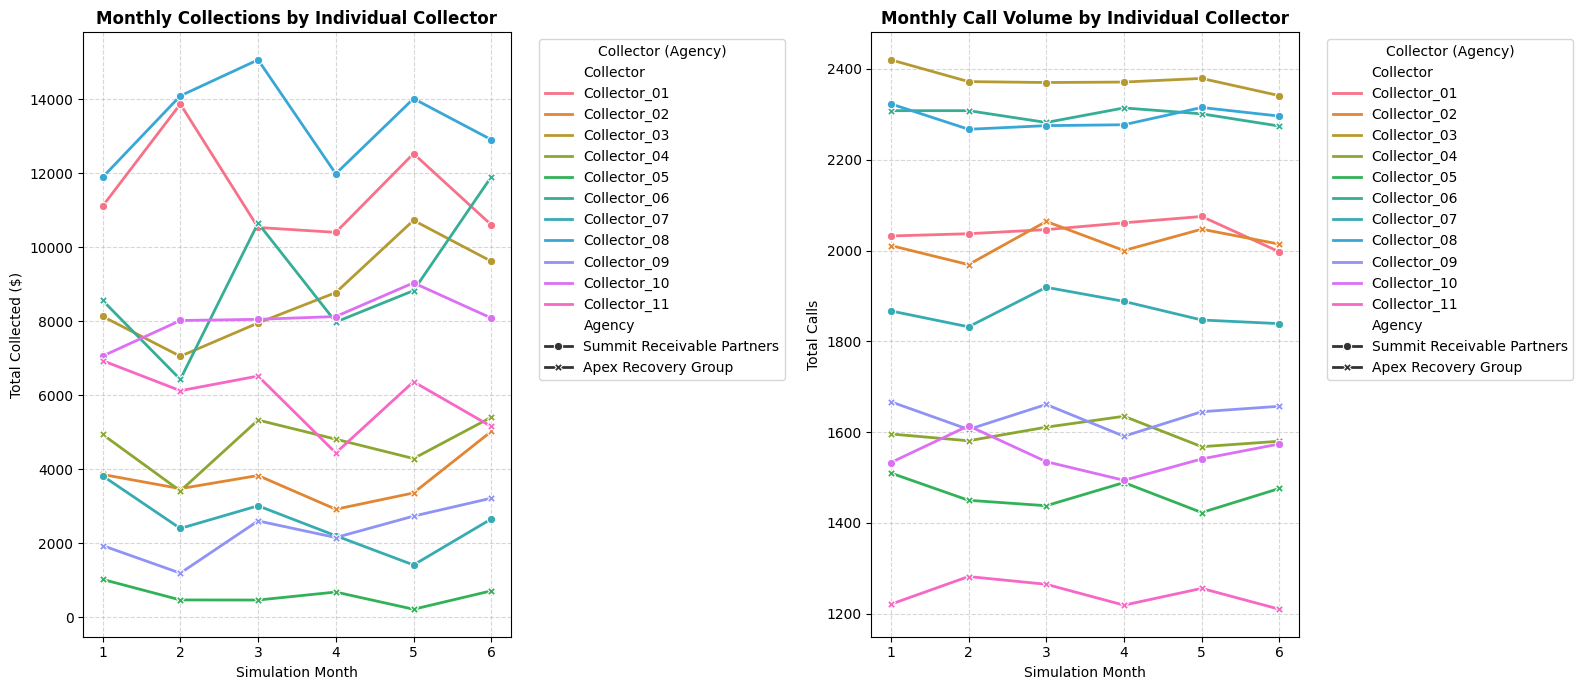

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns

print("--- Generating Collector-Level MoM KPI Visualization ---")

# Group simulation data by Month and Collector
collector_trends = df_sim.groupby(['Month', 'Collector', 'Agency']).agg({
    'Calls': 'sum',
    'Amount_Collected': 'sum'
}).reset_index()

# Create plots for individual collector tracking
plt.figure(figsize=(16, 7))

# 1. Collector Collections Trend
plt.subplot(1, 2, 1)
sns.lineplot(
    data=collector_trends,
    x='Month',
    y='Amount_Collected',
    hue='Collector',
    style='Agency',
    markers=True,
    dashes=False,
    linewidth=2
)
plt.title('Monthly Collections by Individual Collector', fontsize=12, fontweight='bold')
plt.xlabel('Simulation Month', fontsize=10)
plt.ylabel('Total Collected ($)', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', title='Collector (Agency)')

# 2. Collector Calls Trend
plt.subplot(1, 2, 2)
sns.lineplot(
    data=collector_trends,
    x='Month',
    y='Calls',
    hue='Collector',
    style='Agency',
    markers=True,
    dashes=False,
    linewidth=2
)
plt.title('Monthly Call Volume by Individual Collector', fontsize=12, fontweight='bold')
plt.xlabel('Simulation Month', fontsize=10)
plt.ylabel('Total Calls', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', title='Collector (Agency)')

plt.tight_layout()
plt.show()

In [32]:
import pandas as pd

print("--- Collector Performance Summary Statistics by Agency ---")

# Group by Agency and Collector to calculate performance metrics
collector_summary = df_sim.groupby(['Agency', 'Collector']).agg(
    Total_Calls=('Calls', 'sum'),
    Total_Amount_Collected=('Amount_Collected', 'sum'),
    Avg_Daily_Calls=('Calls', 'mean'),
    Avg_Daily_Collection=('Amount_Collected', 'mean')
).reset_index()

# Calculate additional performance efficiency metric: Collection per Call
collector_summary['Collection_Per_Call'] = collector_summary['Total_Amount_Collected'] / collector_summary['Total_Calls']

# Format numbers for better readability
collector_summary['Total_Amount_Collected'] = collector_summary['Total_Amount_Collected'].round(2)
col_sum_styled = collector_summary.sort_values(by=['Agency', 'Total_Amount_Collected'], ascending=[True, False])

display(col_sum_styled)

--- Collector Performance Summary Statistics by Agency ---


,Agency,Collector,Total_Calls,Total_Amount_Collected,Avg_Daily_Calls,Avg_Daily_Collection,Collection_Per_Call
3,Apex Recovery Group,Collector_06,13787,54382.53,76.594444,302.125174,3.944479
5,Apex Recovery Group,Collector_11,7453,35567.49,41.405556,197.597148,4.772238
1,Apex Recovery Group,Collector_04,9571,28217.44,53.172222,156.763565,2.948223
0,Apex Recovery Group,Collector_02,12105,22490.37,67.250000,124.946509,1.857941
4,Apex Recovery Group,Collector_09,9827,13861.24,54.594444,77.006907,1.410526
2,Apex Recovery Group,Collector_05,8786,3589.14,48.811111,19.939683,0.408507
9,Summit Receivable Partners,Collector_08,13753,79994.49,76.405556,444.413826,5.816512
6,Summit Receivable Partners,Collector_01,12248,69085.39,68.044444,383.807737,5.640545
7,Summit Receivable Partners,Collector_03,14253,52288.85,79.183333,290.493628,3.668621
10,Summit Receivable Partners,Collector_10,9291,48410.38,51.616667,268.946529,5.210459


--- Generating KPI Dashboard for Agent Gamma (Summit Receivable Partners) ---


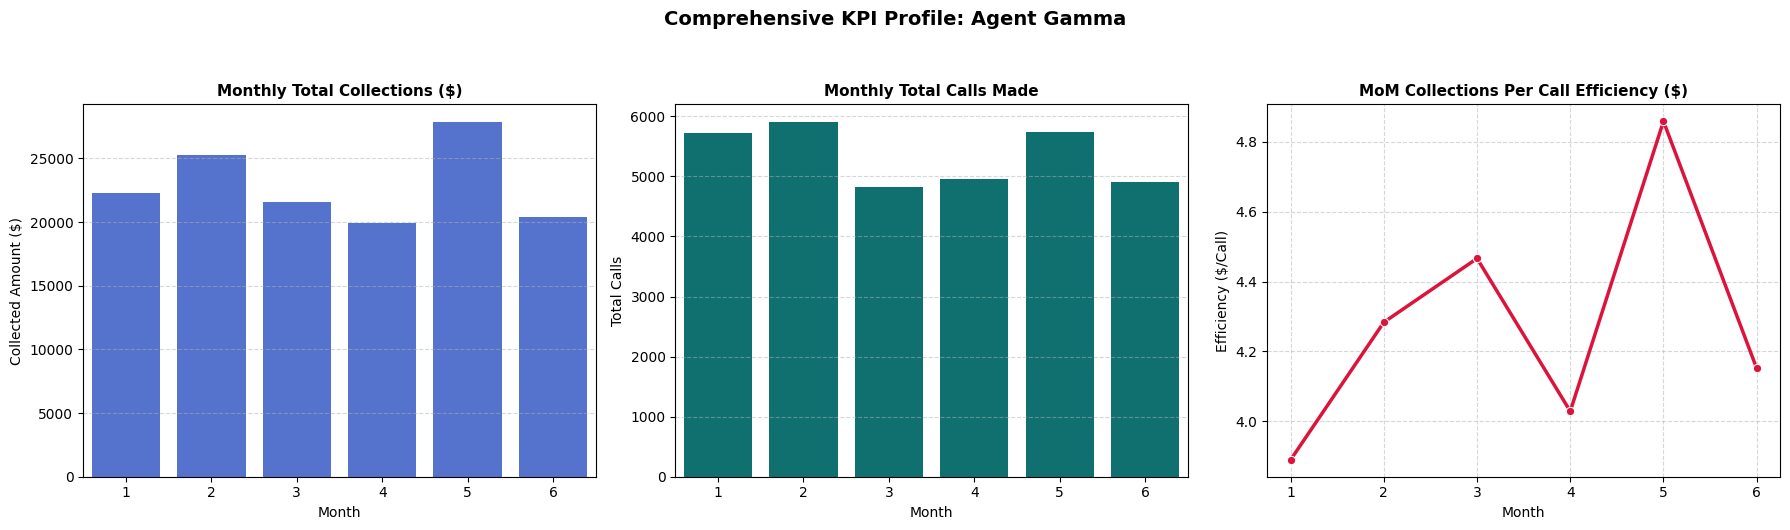

In [33]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select the agent to profile
target_agent = 'Agent Gamma'

# Filter the trends for this specific agent
agent_profile = agent_trends[agent_trends['Agent'] == target_agent].sort_values('Month')

print(f"--- Generating KPI Dashboard for {target_agent} ({agent_profile['Agency'].iloc[0]}) ---")

# Create a multi-panel dashboard
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Monthly Collections
sns.barplot(ax=axes[0], data=agent_profile, x='Month', y='Amount_Collected', color='royalblue')
axes[0].set_title('Monthly Total Collections ($)', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Month')
axes[0].set_ylabel('Collected Amount ($)')
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

# 2. Monthly Call Volume
sns.barplot(ax=axes[1], data=agent_profile, x='Month', y='Calls', color='teal')
axes[1].set_title('Monthly Total Calls Made', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Month')
axes[1].set_ylabel('Total Calls')
axes[1].grid(axis='y', linestyle='--', alpha=0.5)

# 3. Efficiency Metric: Collection per Call
sns.lineplot(ax=axes[2], data=agent_profile, x='Month', y='Collection_Per_Call', color='crimson', marker='o', linewidth=2.5)
axes[2].set_title('MoM Collections Per Call Efficiency ($)', fontsize=11, fontweight='bold')
axes[2].set_xlabel('Month')
axes[2].set_ylabel('Efficiency ($/Call)')
axes[2].grid(True, linestyle='--', alpha=0.5)

plt.suptitle(f'Comprehensive KPI Profile: {target_agent}', fontsize=14, fontweight='bold', y=1.05)
plt.tight_layout()
plt.show()